# Handwritten Digit Recognition using Neural Networks (MNIST)

**Naviotech Solution · AI Internship Project (September 2026 batch)**

**Goal:** train a neural network that recognises handwritten digits (0–9) from 28×28 grayscale images, reach more than 95% accuracy, and let a user draw or upload their own digit for the model to read.

| Phase | In this notebook |
|---|---|
| 1 · Data collection | Load MNIST (70,000 images) and explore samples |
| 2 · Data preprocessing | Normalise pixels to 0–1, reshape, hold out a validation set |
| 3 · Model development | Dense neural network: 784 → 128 → 64 → 10 |
| 4 · Model training | Adam optimiser, early stopping, accuracy and loss curves |
| 5 · Testing and evaluation | Accuracy, precision, recall, F1, confusion matrix, error analysis |
| ➕ Improved model | Convolutional neural network (CNN) and comparison with classical ML |
| 6 · Prediction | Draw a digit on screen or upload a photo, and see the prediction |

> Tip: in Google Colab choose **Runtime → Change runtime type → T4 GPU** to train the CNN faster (CPU also works).

## 0 · Setup – libraries and random seeds

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

SEED = 42
keras.utils.set_random_seed(SEED)              # same results on every run
tf.config.experimental.enable_op_determinism()
os.makedirs("figures", exist_ok=True)          # charts are saved here for the report
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## Phase 1 · Data collection

**MNIST** (Modified National Institute of Standards and Technology) contains 70,000 handwritten digits written by American high-school students and Census Bureau employees, collected by LeCun, Cortes and Burges. Each image is **28 × 28 pixels**, grayscale, with the digit in white on a black background.

* 60,000 training images · 10,000 test images
* Labels: the digit 0–9

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train_full.shape, "| labels:", y_train_full.shape)
print("Test images    :", x_test.shape, "| labels:", y_test.shape)
print("Data type      :", x_train_full.dtype, "| pixel range:", x_train_full.min(), "to", x_train_full.max())
print("Unique labels  :", np.unique(y_train_full))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28) | labels: (60000,)
Test images    : (10000, 28, 28) | labels: (10000,)
Data type      : uint8 | pixel range: 0 to 255
Unique labels  : [0 1 2 3 4 5 6 7 8 9]


### One image is just a 28 × 28 grid of numbers

Label of image 10: 3 | shape: (28, 28)


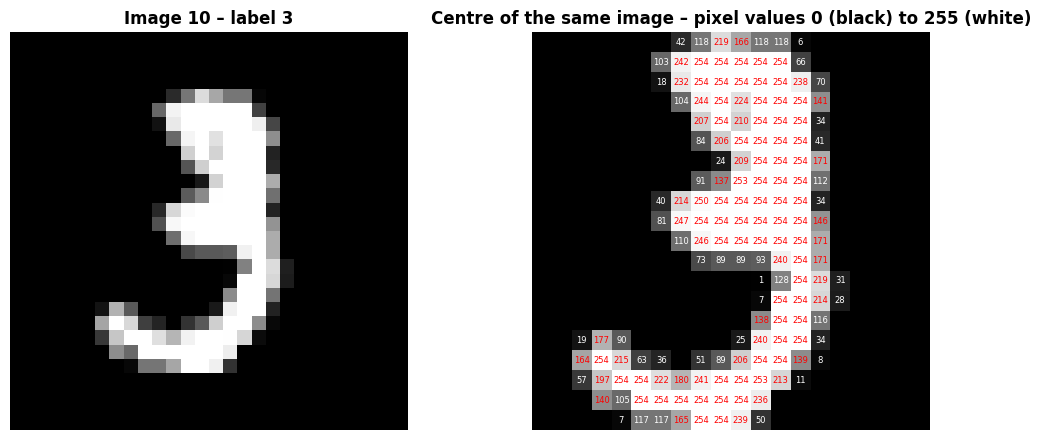

In [3]:
img, label = x_train_full[10], y_train_full[10]
print("Label of image 10:", label, "| shape:", img.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].imshow(img, cmap="gray"); axes[0].set_title(f"Image 10 – label {label}"); axes[0].axis("off")
axes[1].imshow(img[4:24, 4:24], cmap="gray")
for i in range(20):
    for j in range(20):
        v = img[4 + i, 4 + j]
        if v: axes[1].text(j, i, v, ha="center", va="center", fontsize=6, color="red" if v > 128 else "white")
axes[1].set_title("Centre of the same image – pixel values 0 (black) to 255 (white)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

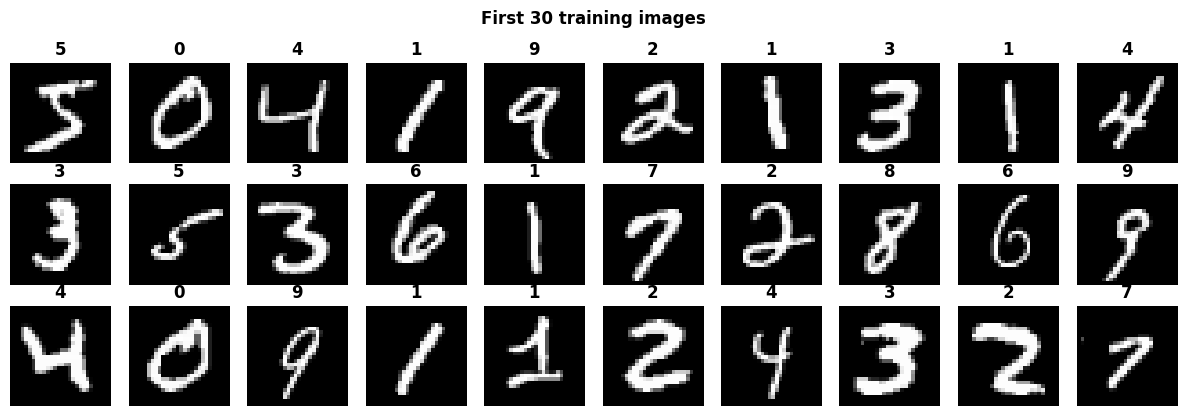

In [4]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4.2))
for ax, im, lb in zip(axes.ravel(), x_train_full[:30], y_train_full[:30]):
    ax.imshow(im, cmap="gray"); ax.set_title(lb); ax.axis("off")
plt.suptitle("First 30 training images", fontweight="bold"); plt.tight_layout()
plt.savefig("figures/sample_images.png", dpi=150, bbox_inches="tight"); plt.show()

digit     0     1     2     3     4     5     6     7     8     9
train  5923  6742  5958  6131  5842  5421  5918  6265  5851  5949
test    980  1135  1032  1010   982   892   958  1028   974  1009


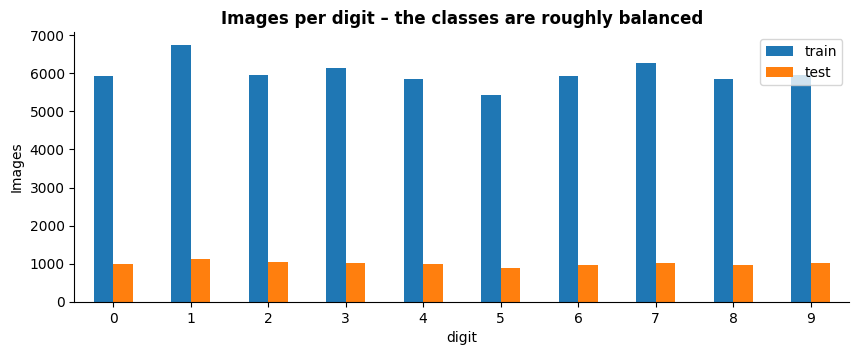

In [5]:
counts = pd.DataFrame({"train": np.bincount(y_train_full), "test": np.bincount(y_test)})
counts.index.name = "digit"
print(counts.T)
counts.plot.bar(figsize=(10, 3.5), rot=0, title="Images per digit – the classes are roughly balanced")
plt.ylabel("Images"); plt.savefig("figures/class_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

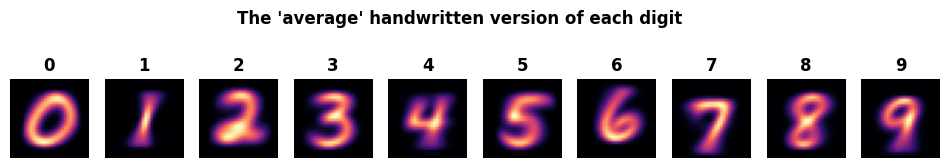

In [6]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for d, ax in enumerate(axes):
    ax.imshow(x_train_full[y_train_full == d].mean(0), cmap="magma"); ax.set_title(d); ax.axis("off")
plt.suptitle("The 'average' handwritten version of each digit", fontweight="bold", y=1.1); plt.show()

## Phase 2 · Data preprocessing

1. **Normalise:** divide pixel values by 255 so they lie between 0 and 1. Small, similar-sized inputs make training faster and more stable.
2. **Validation set:** hold out 6,000 of the 60,000 training images (stratified, so every digit keeps its share). The network never trains on them; early stopping watches them. The 10,000 test images stay untouched until the final evaluation.
3. **Reshape:** the dense network flattens each 28×28 image into 784 numbers inside the model. The CNN needs an explicit channel axis: 28×28 → 28×28×1.

The labels are integers 0–9, so we use `sparse_categorical_crossentropy` and do not need one-hot encoding.

In [7]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("Pixel range after scaling:", x_train_full.min(), "to", x_train_full.max())

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=6000, stratify=y_train_full, random_state=SEED)
print(f"Train: {x_train.shape} | Validation: {x_val.shape} | Test: {x_test.shape}")

Pixel range after scaling: 0.0 to 1.0
Train: (54000, 28, 28) | Validation: (6000, 28, 28) | Test: (10000, 28, 28)


## Phase 3 · Model development – dense neural network

| Layer | Output | Activation | Purpose |
|---|---|---|---|
| Flatten | 784 | – | turns the 28×28 grid into a list of 784 pixel values |
| Dense | 128 | ReLU | learns combinations of pixels (strokes, curves) |
| Dropout | 128 | – | switches off 20 % of neurons during training to reduce over-fitting |
| Dense | 64 | ReLU | combines those into digit-level patterns |
| Dense (output) | 10 | **Softmax** | one probability per digit; the 10 probabilities add up to 1 |

> The starter code used a *sigmoid* output layer. Softmax is the correct choice for picking one class out of ten with categorical cross-entropy, because it makes the probabilities sum to 1.

In [8]:
def build_mlp():
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28)),
        keras.layers.Flatten(name="flatten"),
        keras.layers.Dense(128, activation="relu", name="hidden_1"),
        keras.layers.Dropout(0.2, name="dropout"),
        keras.layers.Dense(64, activation="relu", name="hidden_2"),
        keras.layers.Dense(10, activation="softmax", name="output"),
    ], name="mnist_dense_nn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

mlp = build_mlp()
mlp.summary()

Model: "mnist_dense_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Phase 4 · Model training

* Batch size 128 → about 422 weight updates per epoch.
* Up to 30 epochs; **early stopping** ends training when the validation loss has not improved for 5 epochs and restores the best weights.

In [9]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
history_mlp = mlp.fit(x_train, y_train, validation_data=(x_val, y_val),
                      epochs=30, batch_size=128, callbacks=[early_stop], verbose=2)

Epoch 1/30
422/422 - 8s - 19ms/step - accuracy: 0.8822 - loss: 0.3993 - val_accuracy: 0.9410 - val_loss: 0.1942
Epoch 2/30
422/422 - 2s - 6ms/step - accuracy: 0.9489 - loss: 0.1728 - val_accuracy: 0.9578 - val_loss: 0.1410
Epoch 3/30
422/422 - 3s - 7ms/step - accuracy: 0.9612 - loss: 0.1309 - val_accuracy: 0.9652 - val_loss: 0.1212
Epoch 4/30
422/422 - 2s - 5ms/step - accuracy: 0.9682 - loss: 0.1060 - val_accuracy: 0.9663 - val_loss: 0.1134
Epoch 5/30
422/422 - 2s - 5ms/step - accuracy: 0.9724 - loss: 0.0897 - val_accuracy: 0.9710 - val_loss: 0.1015
Epoch 6/30
422/422 - 2s - 6ms/step - accuracy: 0.9754 - loss: 0.0777 - val_accuracy: 0.9723 - val_loss: 0.0934
Epoch 7/30
422/422 - 2s - 6ms/step - accuracy: 0.9779 - loss: 0.0690 - val_accuracy: 0.9747 - val_loss: 0.0954
Epoch 8/30
422/422 - 2s - 5ms/step - accuracy: 0.9803 - loss: 0.0621 - val_accuracy: 0.9757 - val_loss: 0.0933
Epoch 9/30
422/422 - 2s - 5ms/step - accuracy: 0.9817 - loss: 0.0555 - val_accuracy: 0.9767 - val_loss: 0.0884


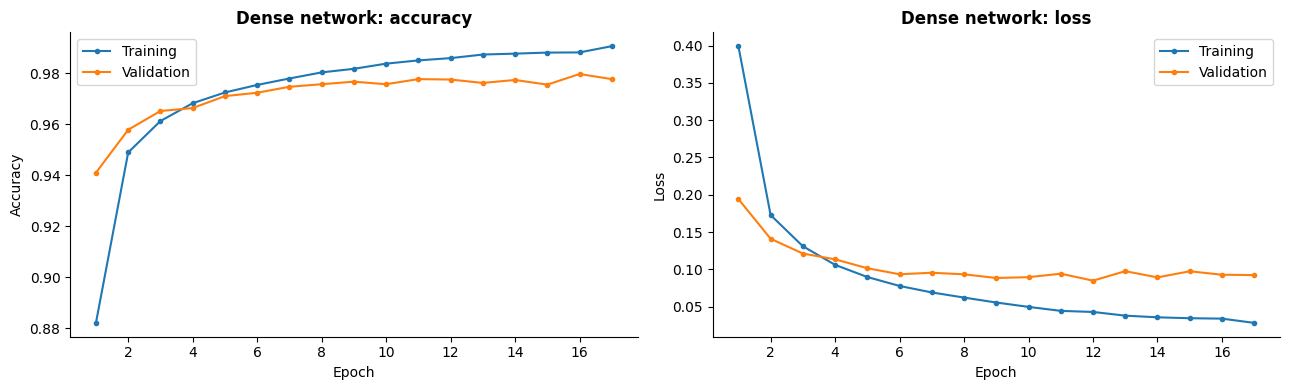

In [10]:
def plot_history(history, title, fname):
    h = history.history; ep = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, k in zip(axes, ["accuracy", "loss"]):
        ax.plot(ep, h[k], "o-", ms=3, label="Training"); ax.plot(ep, h["val_" + k], "o-", ms=3, label="Validation")
        ax.set_xlabel("Epoch"); ax.set_ylabel(k.capitalize()); ax.set_title(f"{title}: {k}"); ax.legend()
    plt.tight_layout(); plt.savefig(f"figures/{fname}", dpi=150, bbox_inches="tight"); plt.show()

plot_history(history_mlp, "Dense network", "training_history_mlp.png")

## Phase 5 · Testing and evaluation on 10,000 unseen images

`model.predict()` returns 10 probabilities per image; `np.argmax` picks the most likely digit.

In [11]:
test_loss, test_acc = mlp.evaluate(x_test, y_test, verbose=0)
probs_mlp = mlp.predict(x_test, verbose=0)
pred_mlp = np.argmax(probs_mlp, axis=1)

print("Probabilities for the first test image:", probs_mlp[0].round(3))
print("Predicted:", pred_mlp[0], "| true label:", y_test[0])
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}   Errors: {(pred_mlp != y_test).sum()} of {len(y_test)}")

Probabilities for the first test image: [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
Predicted: 7 | true label: 7

Test loss: 0.0722   Test accuracy: 0.9793   Errors: 207 of 10000


In [12]:
def report(y_true, y_pred, name):
    print(f"{name}")
    print(f"  Accuracy          : {accuracy_score(y_true, y_pred):.4f}")
    print(f"  Precision (macro) : {precision_score(y_true, y_pred, average='macro'):.4f}")
    print(f"  Recall (macro)    : {recall_score(y_true, y_pred, average='macro'):.4f}")
    print(f"  F1-score (macro)  : {f1_score(y_true, y_pred, average='macro'):.4f}\n")
    print(classification_report(y_true, y_pred, digits=4))

report(y_test, pred_mlp, "Dense neural network – test set")

Dense neural network – test set
  Accuracy          : 0.9793
  Precision (macro) : 0.9792
  Recall (macro)    : 0.9791
  F1-score (macro)  : 0.9791

              precision    recall  f1-score   support

           0     0.9858    0.9888    0.9873       980
           1     0.9920    0.9894    0.9907      1135
           2     0.9863    0.9767    0.9815      1032
           3     0.9659    0.9802    0.9730      1010
           4     0.9866    0.9715    0.9790       982
           5     0.9764    0.9742    0.9753       892
           6     0.9802    0.9802    0.9802       958
           7     0.9731    0.9844    0.9787      1028
           8     0.9675    0.9774    0.9724       974
           9     0.9780    0.9683    0.9731      1009

    accuracy                         0.9793     10000
   macro avg     0.9792    0.9791    0.9791     10000
weighted avg     0.9794    0.9793    0.9793     10000



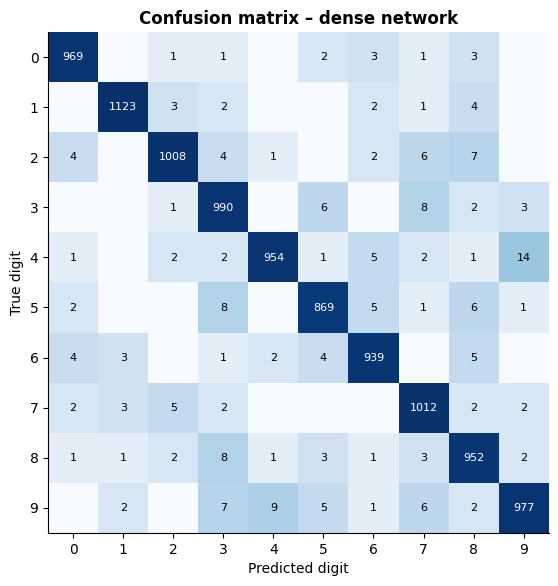

Most common mistake: 14 images of a 4 were read as 9


In [13]:
def plot_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    ax.imshow(np.log1p(cm), cmap="Blues")
    for i in range(10):
        for j in range(10):
            if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                                 color="white" if i == j else "black")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("Predicted digit"); ax.set_ylabel("True digit"); ax.set_title(title)
    plt.savefig(f"figures/{fname}", dpi=150, bbox_inches="tight"); plt.show()
    off = cm.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"Most common mistake: {off[i, j]} images of a {i} were read as {j}")

plot_confusion(y_test, pred_mlp, "Confusion matrix – dense network", "confusion_matrix_mlp.png")

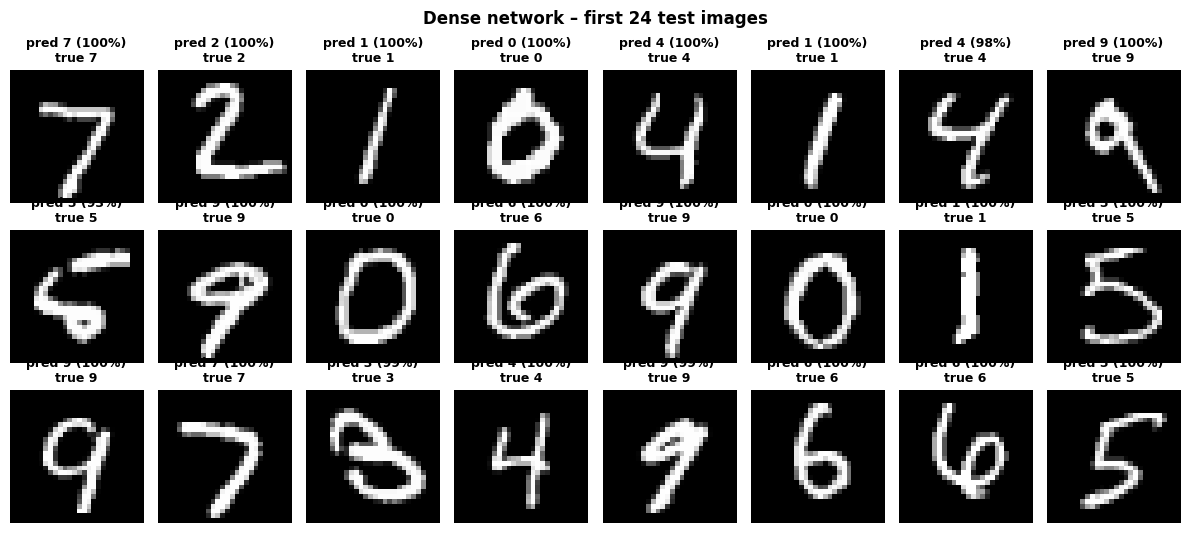

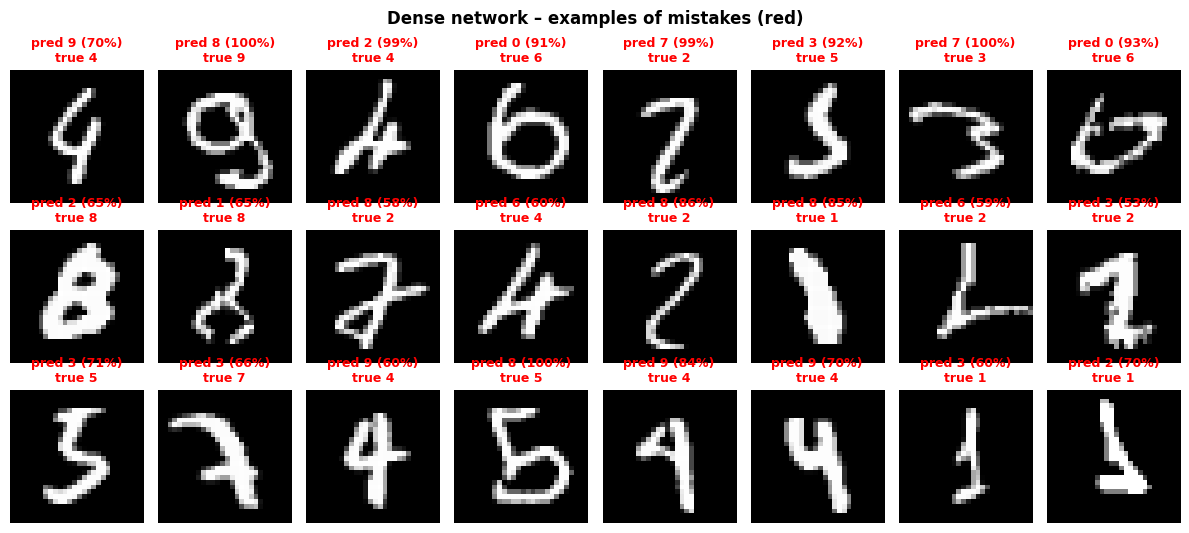

In [14]:
def show_predictions(idx, probs, title, fname):
    pred = probs.argmax(1); conf = probs.max(1)
    fig, axes = plt.subplots(3, 8, figsize=(12, 5.4))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(x_test[i], cmap="gray")
        ok = pred[i] == y_test[i]
        ax.set_title(f"pred {pred[i]} ({conf[i]:.0%})\ntrue {y_test[i]}", fontsize=9, color="black" if ok else "red")
    plt.suptitle(title, fontweight="bold"); plt.tight_layout()
    plt.savefig(f"figures/{fname}", dpi=150, bbox_inches="tight"); plt.show()

show_predictions(range(24), probs_mlp, "Dense network – first 24 test images", "predictions_mlp.png")
show_predictions(np.where(pred_mlp != y_test)[0][:24], probs_mlp, "Dense network – examples of mistakes (red)", "mistakes_mlp.png")

## Improved model · Convolutional neural network (CNN)

A dense network treats the image as a flat list of pixels and does not know which pixels are neighbours. A **CNN** slides small 3×3 filters across the image to detect local patterns (edges, curves, loops) wherever they appear, then **max-pooling** shrinks the image while keeping the strongest signals. This is the standard architecture for image recognition.

| Layer | Output shape | Parameters |
|---|---|---|
| Conv2D 32 filters 3×3, ReLU | 26 × 26 × 32 | 320 |
| MaxPooling 2×2 | 13 × 13 × 32 | 0 |
| Conv2D 64 filters 3×3, ReLU | 11 × 11 × 64 | 18,496 |
| MaxPooling 2×2 | 5 × 5 × 64 | 0 |
| Flatten → Dropout 0.5 | 1,600 | 0 |
| Dense 10, Softmax | 10 | 16,010 |

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
422/422 - 5s - 12ms/step - accuracy: 0.8941 - loss: 0.3549 - val_accuracy: 0.9713 - val_loss: 0.1038
Epoch 2/15
422/422 - 3s - 7ms/step - accuracy: 0.9661 - loss: 0.1065 - val_accuracy: 0.9793 - val_loss: 0.0748
Epoch 3/15
422/422 - 3s - 6ms/step - accuracy: 0.9748 - loss: 0.0822 - val_accuracy: 0.9815 - val_loss: 0.0634
Epoch 4/15
422/422 - 4s - 10ms/step - accuracy: 0.9785 - loss: 0.0692 - val_accuracy: 0.9842 - val_loss: 0.0566
Epoch 5/15
422/422 - 3s - 7ms/step - accuracy: 0.9807 - loss: 0.0625 - val_accuracy: 0.9850 - val_loss: 0.0525
Epoch 6/15
422/422 - 3s - 6ms/step - accuracy: 0.9823 - loss: 0.0558 - val_accuracy: 0.9862 - val_loss: 0.0507
Epoch 7/15
422/422 - 3s - 6ms/step - accuracy: 0.9845 - loss: 0.0502 - val_accuracy: 0.9868 - val_loss: 0.0460
Epoch 8/15
422/422 - 3s - 6ms/step - accuracy: 0.9854 - loss: 0.0469 - val_accuracy: 0.9883 - val_loss: 0.0439
Epoch 9/15
422/422 - 3s - 7ms/step - accuracy: 0.9863 - loss: 0.0442 - val_accuracy: 0.9868 - val_loss: 0.0458

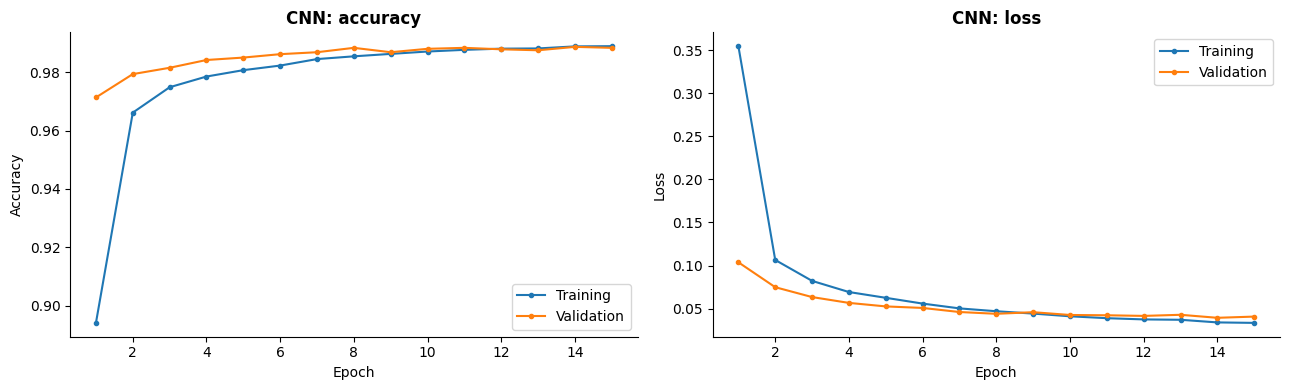

In [15]:
def build_cnn():
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Conv2D(32, (3, 3), activation="relu", name="conv_1"),
        keras.layers.MaxPooling2D((2, 2), name="pool_1"),
        keras.layers.Conv2D(64, (3, 3), activation="relu", name="conv_2"),
        keras.layers.MaxPooling2D((2, 2), name="pool_2"),
        keras.layers.Flatten(name="flatten"),
        keras.layers.Dropout(0.5, name="dropout"),
        keras.layers.Dense(10, activation="softmax", name="output"),
    ], name="mnist_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.summary()
history_cnn = cnn.fit(x_train[..., np.newaxis], y_train, validation_data=(x_val[..., np.newaxis], y_val),
                      epochs=15, batch_size=128, verbose=2,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1)])
plot_history(history_cnn, "CNN", "training_history_cnn.png")

Convolutional neural network – test set
  Accuracy          : 0.9919
  Precision (macro) : 0.9919
  Recall (macro)    : 0.9918
  F1-score (macro)  : 0.9918

              precision    recall  f1-score   support

           0     0.9939    0.9980    0.9959       980
           1     0.9947    0.9965    0.9956      1135
           2     0.9885    0.9952    0.9918      1032
           3     0.9970    0.9911    0.9940      1010
           4     0.9949    0.9949    0.9949       982
           5     0.9844    0.9910    0.9877       892
           6     0.9979    0.9875    0.9927       958
           7     0.9873    0.9854    0.9864      1028
           8     0.9928    0.9908    0.9918       974
           9     0.9871    0.9881    0.9876      1009

    accuracy                         0.9919     10000
   macro avg     0.9919    0.9918    0.9918     10000
weighted avg     0.9919    0.9919    0.9919     10000



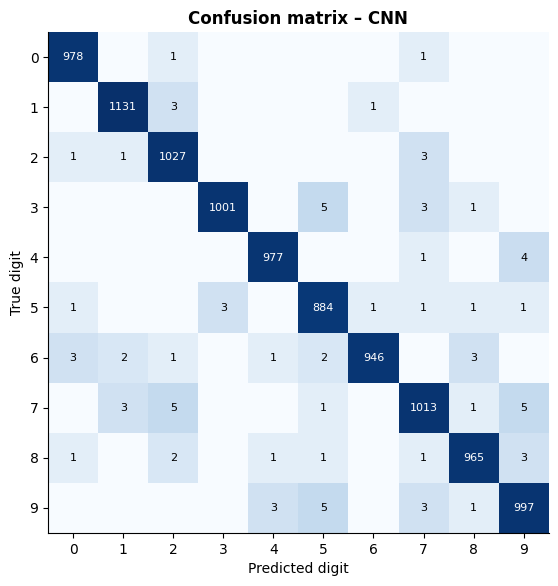

Most common mistake: 5 images of a 3 were read as 5


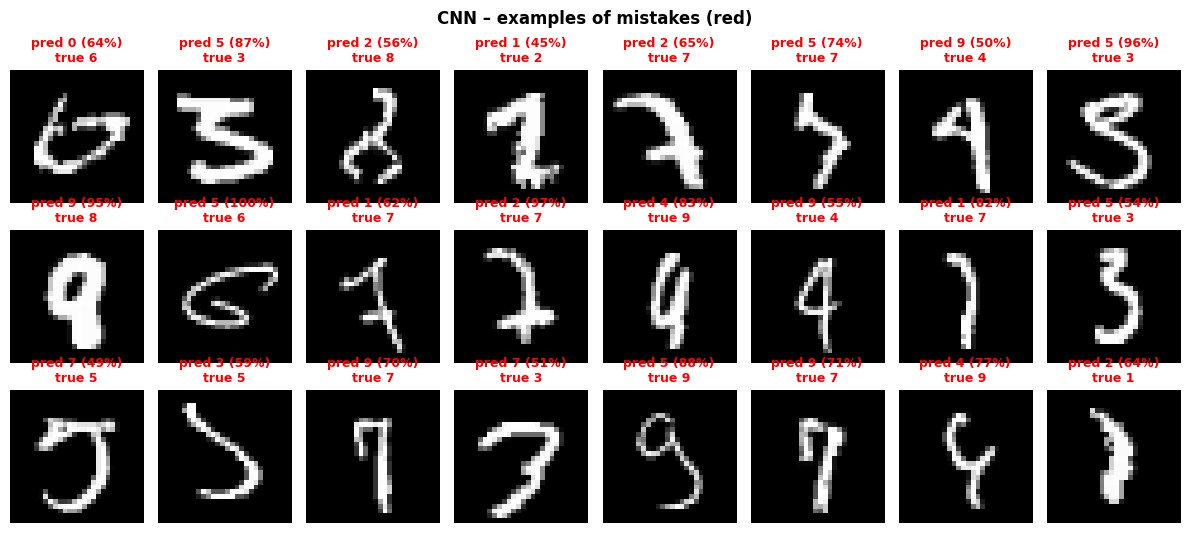

In [16]:
probs_cnn = cnn.predict(x_test[..., np.newaxis], verbose=0)
pred_cnn = probs_cnn.argmax(1)
report(y_test, pred_cnn, "Convolutional neural network – test set")
plot_confusion(y_test, pred_cnn, "Confusion matrix – CNN", "confusion_matrix_cnn.png")
show_predictions(np.where(pred_cnn != y_test)[0][:24], probs_cnn, "CNN – examples of mistakes (red)", "mistakes_cnn.png")

### Comparison with classical machine learning

The same flattened pixels are given to three classical algorithms. (This cell takes 2–4 minutes.)

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

X_tr, X_te = x_train.reshape(len(x_train), -1), x_test.reshape(len(x_test), -1)
scores = {"Dense neural network": accuracy_score(y_test, pred_mlp),
          "Convolutional neural network": accuracy_score(y_test, pred_cnn)}
for name, clf in {"Logistic Regression": LogisticRegression(max_iter=200, random_state=SEED),
                  "K-Nearest Neighbours (k=3)": KNeighborsClassifier(n_neighbors=3, n_jobs=-1),
                  "Random Forest (100 trees)": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)}.items():
    clf.fit(X_tr, y_train); scores[name] = accuracy_score(y_test, clf.predict(X_te)); print(f"{name}: {scores[name]:.4f}")

comparison = pd.Series(scores, name="Test accuracy").sort_values(ascending=False)
comparison.map("{:.2%}".format).to_frame()

Logistic Regression: 0.9245
K-Nearest Neighbours (k=3): 0.9699
Random Forest (100 trees): 0.9696


,Test accuracy
Convolutional neural network,99.19%
Dense neural network,97.93%
K-Nearest Neighbours (k=3),96.99%
Random Forest (100 trees),96.96%
Logistic Regression,92.45%


## Phase 6 · Prediction system – read *your* handwriting

MNIST digits are white on black, fitted into a 20×20 box and centred by their centre of mass. A photo or drawing must be converted the same way, otherwise the model sees something very different from what it learned:

1. Convert to grayscale, make the digit white on black (invert light paper) and remove the paper's background level and noise
2. Crop to the digit
3. Resize so the longer side is 20 pixels, keeping the shape
4. Place it in a 28×28 frame, centred by its centre of mass, and scale to 0–1

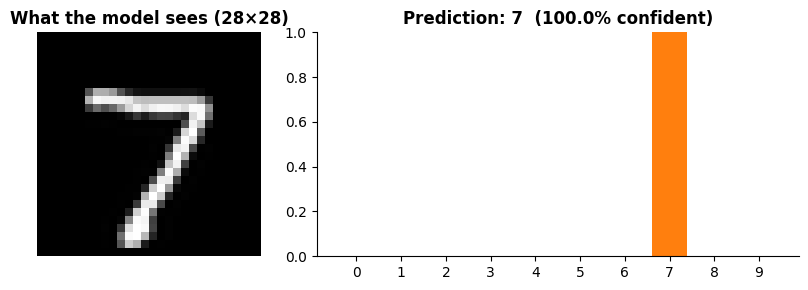

Predicted digit: 7  | next most likely: 2 (0.0%), 3 (0.0%)


7

In [18]:
from PIL import Image

def prepare_image(source):
    img = source if isinstance(source, Image.Image) else Image.open(source)
    if img.mode in ("RGBA", "LA"):
        bg = Image.new("RGBA", img.size, (255, 255, 255, 255)); img = Image.alpha_composite(bg, img.convert("RGBA"))
    gray = np.asarray(img.convert("L"), dtype=np.float32)
    if np.median(gray) > 127:                 # light background -> invert
        gray = 255.0 - gray
    gray = np.clip(gray - np.median(gray), 0, None)   # remove paper level
    peak = np.percentile(gray, 99.9)
    if peak <= 0: raise ValueError("No digit found in the image")
    gray[gray < 0.15 * peak] = 0                       # remove faint noise
    ys, xs = np.nonzero(gray >= 0.3 * peak)            # clearly inked pixels
    crop = np.clip(gray[ys.min():ys.max() + 1, xs.min():xs.max() + 1] * (255.0 / peak), 0, 255)
    h, w = crop.shape; s = 20.0 / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = np.asarray(Image.fromarray(crop.astype(np.uint8)).resize((nw, nh), Image.LANCZOS), dtype=np.float32)
    canvas = np.zeros((28, 28), np.float32)
    top, left = (28 - nh) // 2, (28 - nw) // 2
    canvas[top:top + nh, left:left + nw] = small
    rows, cols = np.indices(canvas.shape); total = canvas.sum()
    cy, cx = (rows * canvas).sum() / total, (cols * canvas).sum() / total
    canvas = np.roll(np.roll(canvas, int(round(14 - cy)), 0), int(round(14 - cx)), 1)
    return canvas / canvas.max()

def predict_digit(source, model=cnn):
    x = prepare_image(source)
    p = model.predict(x[np.newaxis, ..., np.newaxis], verbose=0)[0]
    top3 = np.argsort(p)[::-1][:3]
    fig, axes = plt.subplots(1, 2, figsize=(8, 3), gridspec_kw={"width_ratios": [1, 2]})
    axes[0].imshow(x, cmap="gray"); axes[0].set_title("What the model sees (28×28)"); axes[0].axis("off")
    axes[1].bar(range(10), p, color=["tab:orange" if d == top3[0] else "tab:blue" for d in range(10)])
    axes[1].set_xticks(range(10)); axes[1].set_ylim(0, 1); axes[1].set_title(f"Prediction: {top3[0]}  ({p[top3[0]]:.1%} confident)")
    plt.tight_layout(); plt.show()
    print(f"Predicted digit: {top3[0]}  | next most likely: " + ", ".join(f"{d} ({p[d]:.1%})" for d in top3[1:]))
    return int(top3[0])

# Test on an MNIST test image, made to look like a user drawing (dark digit on white, larger)
sample = Image.fromarray((255 - x_test[0] * 255).astype(np.uint8)).resize((200, 200))
predict_digit(sample)

### Option A – draw a digit with your mouse or finger (Google Colab)

Run the cell, draw one digit in the white box, then click **Predict**.

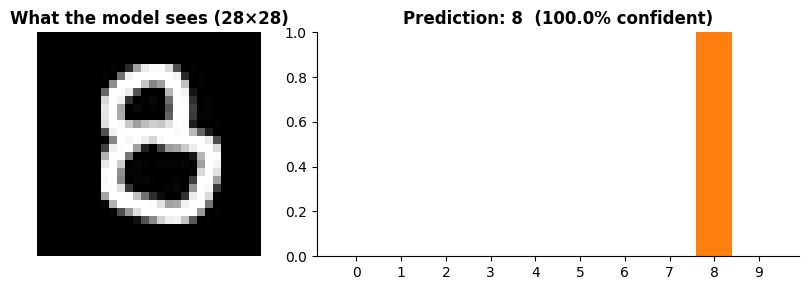

Predicted digit: 8  | next most likely: 0 (0.0%), 6 (0.0%)


In [19]:
try:
    from google.colab.output import eval_js
    from IPython.display import HTML, display
    from base64 import b64decode
    import io

    CANVAS = '''
    <canvas id="c" width="280" height="280" style="border:2px solid #555;border-radius:8px;touch-action:none;background:#fff"></canvas><br>
    <button id="p" style="margin-top:8px;padding:6px 18px">Predict</button>
    <button id="x" style="margin-top:8px;padding:6px 18px">Clear</button>
    <script>
    const c = document.getElementById('c'), g = c.getContext('2d');
    g.fillStyle = '#fff'; g.fillRect(0, 0, 280, 280); g.lineWidth = 20; g.lineCap = 'round'; g.lineJoin = 'round'; g.strokeStyle = '#000';
    let down = false;
    const pos = e => { const r = c.getBoundingClientRect(), t = e.touches ? e.touches[0] : e; return [t.clientX - r.left, t.clientY - r.top]; };
    const start = e => { down = true; const [x, y] = pos(e); g.beginPath(); g.moveTo(x, y); e.preventDefault(); };
    const move = e => { if (!down) return; const [x, y] = pos(e); g.lineTo(x, y); g.stroke(); e.preventDefault(); };
    c.onmousedown = start; c.onmousemove = move; window.onmouseup = () => down = false;
    c.ontouchstart = start; c.ontouchmove = move; c.ontouchend = () => down = false;
    document.getElementById('x').onclick = () => { g.fillStyle = '#fff'; g.fillRect(0, 0, 280, 280); };
    var drawing = new Promise(res => document.getElementById('p').onclick = () => res(c.toDataURL('image/png')));
    </script>'''
    display(HTML(CANVAS))
    data_url = eval_js("drawing")
    drawn = Image.open(io.BytesIO(b64decode(data_url.split(",")[1])))
    predict_digit(drawn)
except ImportError:
    print("The drawing canvas works in Google Colab. In Jupyter, use Option B with an image file.")

### Option B – upload a photo or scan of a handwritten digit

Write a digit with a dark pen on white paper, take a photo, crop it roughly around the digit, and upload it.

Saving mnist_test_50_digit6.png to mnist_test_50_digit6.png

 mnist_test_50_digit6.png


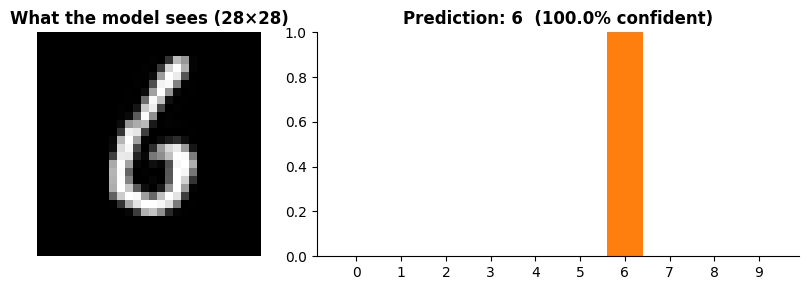

Predicted digit: 6  | next most likely: 5 (0.0%), 8 (0.0%)


In [20]:
try:
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        print("\n", name); predict_digit(name)
except ImportError:
    path = input("Path to an image file (or press Enter to skip): ").strip()
    if path: predict_digit(path)

## Save the trained models

In [21]:
os.makedirs("models", exist_ok=True)
mlp.save("models/mnist_mlp.keras")
cnn.save("models/mnist_cnn.keras")
print("Saved models/mnist_mlp.keras and models/mnist_cnn.keras")

Saved models/mnist_mlp.keras and models/mnist_cnn.keras


## Conclusion

* The **dense neural network** (109,386 parameters) recognises handwritten digits with about **98 % accuracy** on 10,000 unseen test images, above the 95 % target.
* The **convolutional neural network** (34,826 parameters) does better still, at about **99 %**, with fewer parameters, because it learns local shapes such as edges and loops.
* Most remaining mistakes are digits that look alike or are badly written (4 ↔ 9, 3 ↔ 5, 7 ↔ 2).
* The prediction system applies MNIST-style preprocessing, so users can draw or upload their own digits.

**Applications:** bank cheque processing, postal code recognition, OCR systems, educational tools, automated form processing.

**Future scope:** data augmentation (rotation, shifting), deeper CNNs with batch normalisation, recognising multi-digit numbers, and deployment as a web or mobile app.

In [22]:
# Extra outputs for the report (Project 2) - saves my_results.json and model_weights.js
import json, base64
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

def summarise(model, hist, probs, pred, xt):
    h = {k: [round(float(v), 4) for v in vals] for k, vals in hist.history.items()}
    best = int(np.argmin(h["val_loss"]))
    loss, acc = model.evaluate(xt, y_test, verbose=0)
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro")
    _, _, f_cls, _ = precision_recall_fscore_support(y_test, pred, average=None)
    cm = confusion_matrix(y_test, pred)
    conf = probs.max(1); ok = pred == y_test
    off = sorted(((int(cm[i, j]), i, j) for i in range(10) for j in range(10) if i != j), reverse=True)[:5]
    bins = np.linspace(0, 1, 21)
    wrong_idx = np.where(~ok)[0]
    return {"accuracy": float(acc), "test_loss": float(loss), "errors": int((~ok).sum()),
            "precision_macro": float(p), "recall_macro": float(r), "f1_macro": float(f),
            "per_class_accuracy": (cm.diagonal() / cm.sum(1)).round(4).tolist(), "per_class_f1": f_cls.round(4).tolist(),
            "confusion_matrix": cm.tolist(), "top_confusions": [{"true": i, "pred": j, "count": c} for c, i, j in off],
            "params": int(model.count_params()), "epochs_trained": len(h["loss"]), "best_epoch": best + 1, "history": h,
            "confidence": {"conf_ge_099": float((conf >= 0.99).mean()), "acc_conf_ge_099": float(ok[conf >= 0.99].mean()),
                           "n_conf_lt_09": int((conf < 0.9).sum()), "acc_conf_lt_09": float(ok[conf < 0.9].mean()),
                           "wrong_below_09": float((conf[~ok] < 0.9).mean()), "median_conf_wrong": float(np.median(conf[~ok])),
                           "hist_correct": np.histogram(conf[ok], bins)[0].tolist(), "hist_wrong": np.histogram(conf[~ok], bins)[0].tolist()},
            "first24": [[int(pred[i]), round(float(conf[i]), 4)] for i in range(24)],
            "wrong24": [[int(i), int(y_test[i]), int(pred[i]), round(float(conf[i]), 4)] for i in wrong_idx[:24]]}

R = {"Dense neural network": summarise(mlp, history_mlp, probs_mlp, pred_mlp, x_test),
     "Convolutional neural network": summarise(cnn, history_cnn, probs_cnn, pred_cnn, x_test[..., np.newaxis]),
     "comparison": {k: float(v) for k, v in scores.items()}}
with open("my_results.json", "w") as fh: json.dump(R, fh)
for name in ["Dense neural network", "Convolutional neural network"]:
    m = R[name]
    print(f"{name}: accuracy {m['accuracy']:.4f} | errors {m['errors']} | epochs {m['epochs_trained']} (best {m['best_epoch']})")

# Your CNN for the web demo
b64 = lambda a, t: base64.b64encode(np.ascontiguousarray(a, dtype=t).tobytes()).decode()
names = ["conv1_w", "conv1_b", "conv2_w", "conv2_b", "dense_w", "dense_b"]
weights = {n: b64(a, "<f4") for n, a in zip(names, cnn.get_weights())}
samples = [{"label": d, "px": b64(np.round(x_test[int(np.where(y_test == d)[0][0])] * 255), np.uint8)} for d in range(10)]
with open("model_weights.js", "w") as fh:
    fh.write("window.MODEL_WEIGHTS = " + json.dumps(weights) + ";\nwindow.MNIST_SAMPLES = " + json.dumps(samples) + ";\n")

from google.colab import files
files.download("my_results.json"); files.download("model_weights.js")

Dense neural network: accuracy 0.9793 | errors 207 | epochs 17 (best 12)
Convolutional neural network: accuracy 0.9919 | errors 81 | epochs 15 (best 14)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>